# 01 EDA: trips, POIs, and the target

All logic lives in `src/biketrips`; this notebook only calls it. Part 1 iterates on a reproducible 10% sample (hash of trip id, seed 42). Part 2 confirms the key numbers on all ~10M trips with DuckDB.

## EDA findings

- **Data is clean at the row level, dirty at the GPS level.** No null, unparseable or duplicate fields in 9,980,998 trips. 0.15% are dropped: 11,539 have a (0, 0) GPS placeholder, 2,025 start far outside Shenzhen (clusters in other provinces, e.g. 126.4E 43.9N), 318 start in Shenzhen but end outside, 1,406 have zero or over-4h durations.
- **Coordinates mix two datums.** Trips, metro and bus stops are in GCJ-02 (AMap's offset system); POIs, the boundary and the population raster are WGS84. The offset is about 550 m, more than one H3 res-8 edge. Trips and stops are shifted to WGS84 with an offset measured from POIs that carry both.
- **Effective window is 8 days**, 2021-07-31 to 2021-08-07. Jul 28 to 30 have under 100 trips in total. Clear commute peaks at 8:00 and 18:00.
- **Zeros are the norm, not noise.** On the full 3,272-cell grid, 42% of cells have no trip end. Dropping them would hide the hardest part of the problem. 769 zero cells have POIs, and 82% of cells east of 114.25E are zero (they hold 0.8% of trips), which looks like an operator coverage gap (supply), not a lack of demand.
- **Counts are heavily overdispersed**: mean 3,046 vs variance 6.0e7 (ratio about 20,000). A Poisson GLM can still rank cells, but its implied uncertainty is far too narrow.
- **Demand is spatially smooth.** Moran's I is 0.70 on counts and 0.87 on log1p counts; a cell's log count correlates 0.95 with its neighbour mean. A random split leaks this, so we evaluate with spatial blocks and add a spatial kNN baseline.
- **POIs matter broadly.** Most categories have Spearman 0.6 to 0.82 with trip ends; Pass Facilities and Transportation Service lead. The three used by Baseline LR (Sports & Recreation, Transportation, Medical) span 0.72 to 0.82, so using all categories adds breadth more than a missing star feature.
- **1% is too little.** With a 1% sample, 613 of 1,898 cells that do have trips look empty, and the median per-cell error after scaling is 27% (8% at 10%). We use all trips.


In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from biketrips import config, data, features, plots, quality

warnings.filterwarnings("ignore", module="openpyxl")
pd.set_option("display.width", 140)
cfg = config.load_config()
con = data.connect()

## Part 1: preliminary 10% sample

### Schema, dtypes, null rates

In [2]:
data.clean_trips(con, cfg, frac=cfg["eda"]["sample_fraction"])
quality.null_rates(con, "trips_flagged")

,column_name,column_type,count,null_percentage,min,max,approx_unique
0,trip_id,VARCHAR,996873,0.00,6235d85fd9eb0867d7831fab,62360a21d9eb0867d71b6be9,964620
1,user_id,VARCHAR,996873,0.00,00001f2d1fbf9bbabc6ea2**********,fffff64a46675b21651e87**********,659419
2,start_time,TIMESTAMP,996873,0.00,2021-07-28 11:28:25,2021-08-07 19:06:59,410806
3,end_time,TIMESTAMP,996873,0.00,2021-07-28 13:25:14,2021-08-07 19:12:09,402821
4,start_lat,DOUBLE,996873,0.00,0.0,47.6609125,687360
5,start_lng,DOUBLE,996873,0.00,0.0,132.5358773,672557
6,end_lat,DOUBLE,996873,0.00,0.0,40.824753,951353
7,end_lng,DOUBLE,996873,0.00,0.0,120.64064,874422
8,dup_rank,BIGINT,996873,0.00,1,1,1
9,duration_s,BIGINT,996873,0.00,0,26109,8762


### Coordinate validity

Share of trips charged to each cleaning rule (first rule that fails), then where the bad coordinates land.

In [3]:
quality.drop_summary(con)

,reason,n,pct
0,kept,995354,99.8476
1,zero_coords,1149,0.1153
2,start_out_of_bounds,215,0.0216
3,zero_duration,120,0.0120
4,end_out_of_bounds,31,0.0031
5,extreme_duration,4,0.0004


In [4]:
quality.invalid_points(con).head(12)

,drop_reason,side,lng,lat,n
0,zero_coords,start,0.0,0.0,765
1,zero_coords,end,0.0,0.0,384
2,start_out_of_bounds,start,116.2,23.0,45
3,start_out_of_bounds,start,126.4,43.9,23
4,start_out_of_bounds,start,132.5,47.7,21
5,start_out_of_bounds,start,113.6,24.5,21
6,start_out_of_bounds,start,110.5,40.6,15
7,start_out_of_bounds,start,114.5,25.6,11
8,start_out_of_bounds,start,106.5,29.6,11
9,start_out_of_bounds,start,132.0,47.2,8


### Trip duration

0.000        0.000
0.001        9.000
0.010       39.000
0.250      324.000
0.500      511.000
0.750      832.000
0.990     5503.000
0.999    10590.384
1.000    26109.000
Name: duration_s, dtype: float64


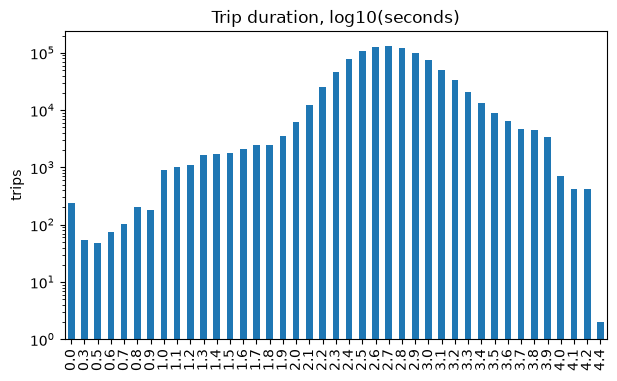

In [5]:
print(quality.durations(con))
plots.bar(quality.duration_hist(con).set_index("log10_s")["n"], title="Trip duration, log10(seconds)", ylabel="trips", log=True);

### Temporal pattern

day         weekday  
2021-07-28  Wednesday         2
2021-07-29  Thursday         14
2021-07-30  Friday           68
2021-07-31  Saturday      89288
2021-08-01  Sunday       133453
2021-08-02  Monday       146028
2021-08-03  Tuesday      154536
2021-08-04  Wednesday    137038
2021-08-05  Thursday     116146
2021-08-06  Friday       138614
2021-08-07  Saturday      80167
Name: n, dtype: int64

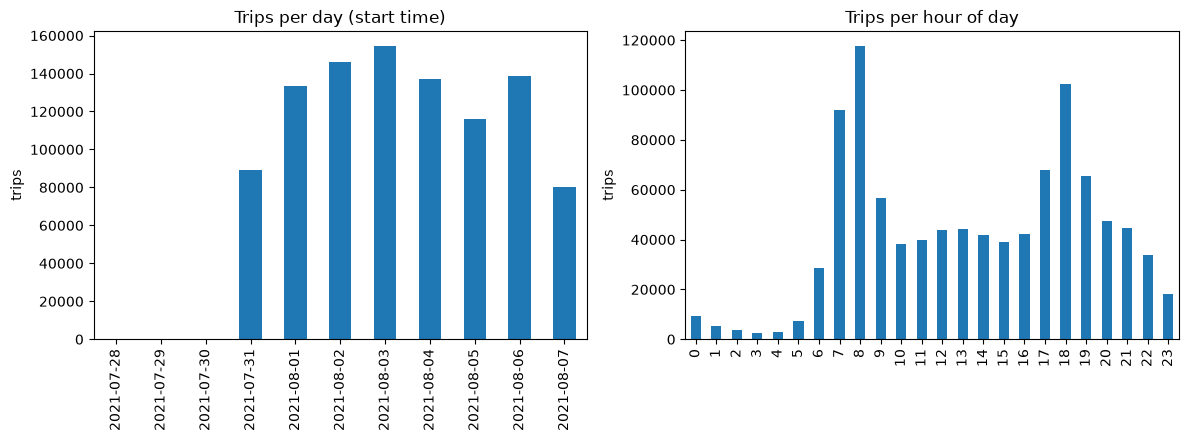

In [6]:
tmp = quality.temporal(con)
plots.temporal(tmp);
tmp.groupby(["day", "weekday"])["n"].sum()

## Part 2: full dataset

Re-run cleaning on all trips with logging, build the full H3 grid over the boundary, and count trip ends per cell. Cells with no trip end get 0.

In [7]:
log = quality.DropLog(cfg["data"]["interim_dir"] / "eda_drop_log.csv")
data.clean_trips(con, cfg, frac=1.0, log=log)
quality.drop_summary(con)

,reason,n,pct
0,kept,9965710,99.8468
1,zero_coords,11539,0.1156
2,start_out_of_bounds,2025,0.0203
3,zero_duration,1356,0.0136
4,end_out_of_bounds,318,0.0032
5,extreme_duration,50,0.0005


In [8]:
res = cfg["features"]["h3_res"]
grid = features.full_grid(data.load_boundary(cfg), res, cfg["features"]["boundary_buffer_deg"])
target = features.trip_target(con, grid, log)
print(len(grid), "cells")
quality.overdispersion(target["trips"])

3272 cells


{'mean': np.float64(3045.591687041565),
 'variance': np.float64(60388746.3094419),
 'var_to_mean': np.float64(19828.247682177807),
 'zero_share': np.float64(0.41992665036674814)}

### Per-cell trip-end counts

Variance far above the mean means a plain Poisson model is overdispersed: its point predictions can still be fine, but its implied uncertainty is far too narrow.

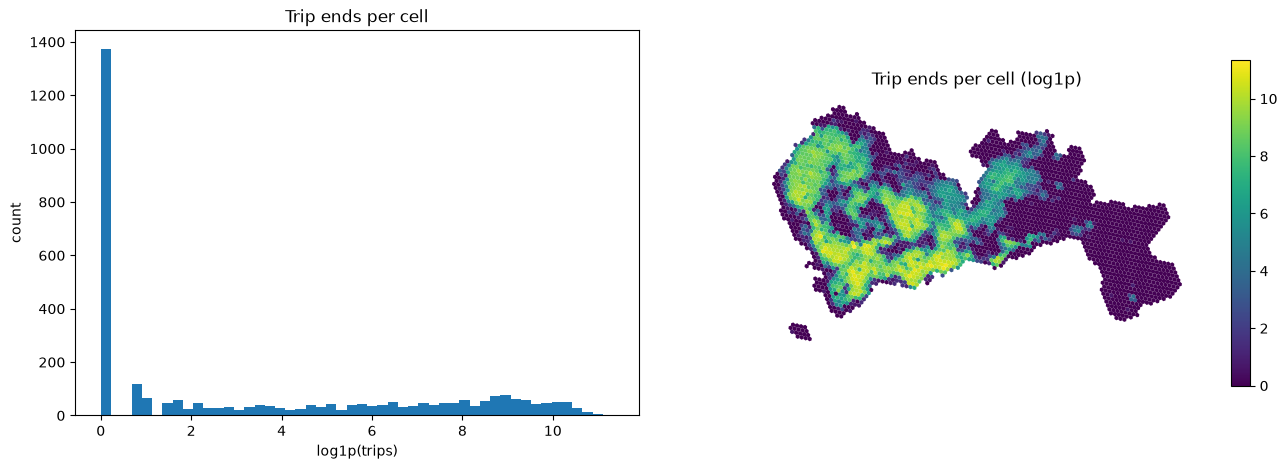

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
plots.hist(np.log1p(target["trips"]), ax[0], title="Trip ends per cell", xlabel="log1p(trips)")
plots.cell_map(target, "trips", ax[1], title="Trip ends per cell", log=True);

### POI categories

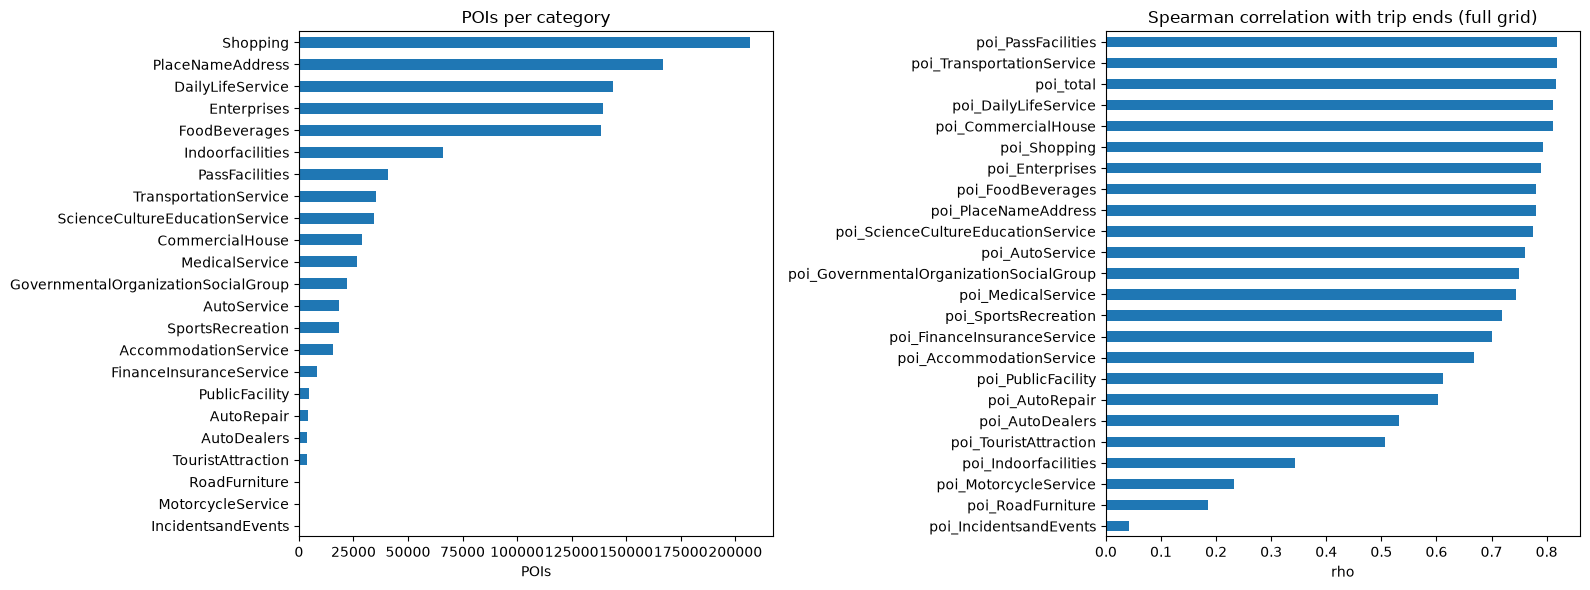

In [10]:
pois = data.load_pois(cfg, log)
metro, bus = data.load_transit(cfg, log)
poi = features.poi_counts(pois, grid, res, log)
cells = target.merge(poi, on="h3")
poi_cols = [c for c in poi.columns if c.startswith("poi_") and c != "poi_total"]
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plots.bar(pois["category"].value_counts().sort_values(), ax[0], "POIs per category", "POIs", horizontal=True)
plots.bar(quality.correlations(cells, poi_cols + ["poi_total"]).sort_values(), ax[1],
          "Spearman correlation with trip ends (full grid)", "rho", horizontal=True)
plt.tight_layout()

### Spatial autocorrelation of the target

Moran's I with H3 k-ring 1 weights. Strong positive autocorrelation means a random split puts near-copies of each test cell in the training set.

Moran's I, trips: 0.703
Moran's I, log1p(trips): 0.871
corr(log1p cell, neighbour mean): 0.951


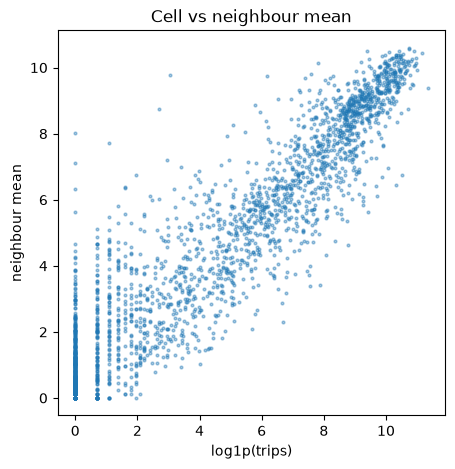

In [11]:
adj = features.neighbors(grid["h3"].tolist())
nbr = features.neighbor_mean(adj, np.log1p(cells["trips"]))
print("Moran's I, trips:", round(features.morans_i(adj, cells["trips"]), 3))
print("Moran's I, log1p(trips):", round(features.morans_i(adj, np.log1p(cells["trips"])), 3))
print("corr(log1p cell, neighbour mean):", round(pd.Series(np.log1p(cells["trips"])).corr(pd.Series(nbr)), 3))
plots.scatter(np.log1p(cells["trips"]), nbr, title="Cell vs neighbour mean", xlabel="log1p(trips)", ylabel="neighbour mean");

### Sample vs full: how noisy is a 1% sample?

Counts from nested hash samples are scaled by 1/fraction and compared with the full count. `false_zero_cells` are cells that look empty in the sample but have real trips.

In [12]:
noise = quality.sample_noise(con, cells, cfg["eda"]["noise_fractions"], cfg["seed"])
noise

,fraction,trips,cells_seen,false_zero_cells,median_rel_error,p90_rel_error,spearman_vs_full
0,0.01,99216,1285,613,0.269293,1.0,0.908127
1,0.10,995303,1592,306,0.077883,1.0,0.962776
2,1.00,9965176,1898,0,0.000000,0.0,1.000000


## Drop and fill log

The same log, extended with population and transit steps, is written to `results/data_quality.md` by `scripts/build_features.py`. This notebook only displays it and does not save.

In [13]:
log.df

,stage,step,action,rows,of,reason
0,trips,raw rows,info,9980998,9980998,100% of 21_1000w.csv
1,trips,missing_id,drop,0,9980998,no trip id
2,trips,duplicate_id,drop,0,9980998,"repeated trip id, first kept"
3,trips,bad_timestamp,drop,0,9980998,null or unparseable timestamp
4,trips,end_before_start,drop,0,9980998,end time before start
5,trips,zero_duration,drop,1356,9980998,duration under min_duration_s
6,trips,extreme_duration,drop,50,9979642,duration over max_duration_s
7,trips,missing_coords,drop,0,9979592,null coordinate
8,trips,zero_coords,drop,11539,9979592,"GPS (0, 0) placeholder"
9,trips,start_out_of_bounds,drop,2025,9968053,start outside Shenzhen bbox
